<a href="https://colab.research.google.com/github/JuanTorresCol/NeuralNetworkImageRecognition/blob/main/JuanTorres_assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This code has been ran on September 13 2026 using release August 6 2026 of Google Colab Pro.

**Part 1- Neural Network**

In [2]:
import numpy as np
import os
import pathlib
import PIL
import PIL.Image
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


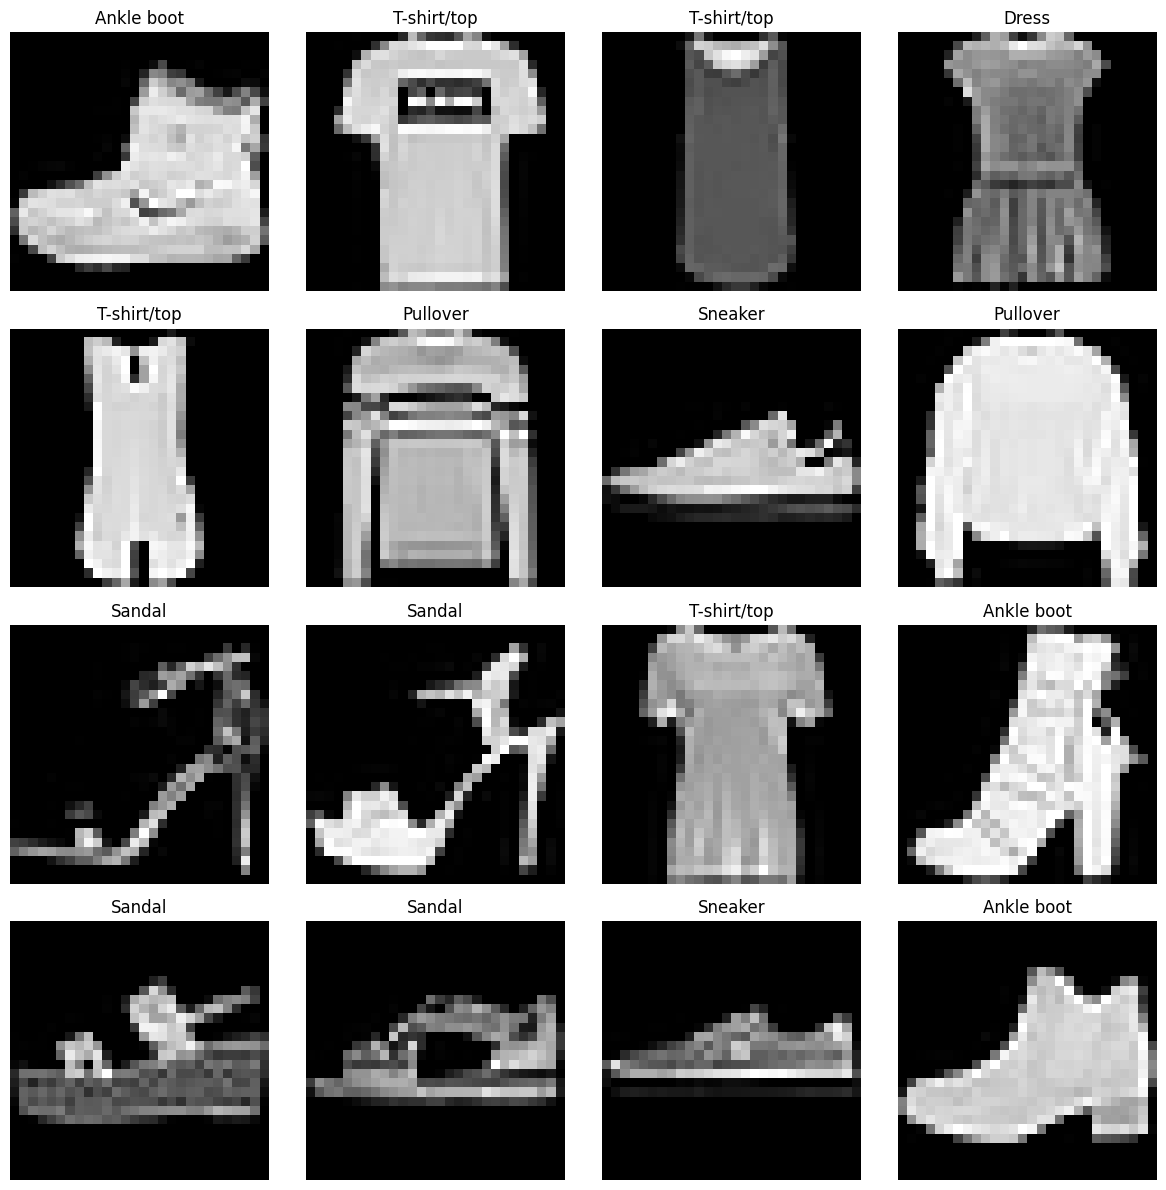

In [4]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()   #Load the dataset here
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']   #These are the labels


# It is always good to see what type of data we are working on
# Write a code to generate following samples with their associated classes

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

plt.figure(figsize=(12, 12))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [5]:
# Images are 28x28. We don't plan to resize them now
IMG_HEIGHT=28
IMG_WIDTH= 28


In [7]:
# Normalize inputs from 0-255 to 0-1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

Training pixel range: 0.0 0.003921569
Test pixel range: 0.0 0.003921569


In [9]:
#Create the model here. It should be an NN model with one hiddenlayer (128 nodes) and Relu activation function. What should be the output activation function?

IMG_HEIGHT = 28
IMG_WIDTH = 28

loss_fn = 'sparse_categorical_crossentropy'

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss=loss_fn,
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Train the model here

# start trauining the model here. We have 20% for validation, 20 epochs and batch sizes are 128
hist = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=128,
    verbose=1
)


Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5318 - loss: 1.6988 - val_accuracy: 0.6717 - val_loss: 1.1727
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6968 - loss: 0.9817 - val_accuracy: 0.7267 - val_loss: 0.8316
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7364 - loss: 0.7689 - val_accuracy: 0.7518 - val_loss: 0.7082
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7553 - loss: 0.6833 - val_accuracy: 0.7639 - val_loss: 0.6503
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7720 - loss: 0.6349 - val_accuracy: 0.7753 - val_loss: 0.6112
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7846 - loss: 0.6007 - val_accuracy: 0.7856 - val_loss: 0.5853
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7950 - loss: 0.5740 - val_accuracy: 0.7957 - val_loss: 0.5639
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8042 - loss: 0.5529 - val_accuracy: 0.

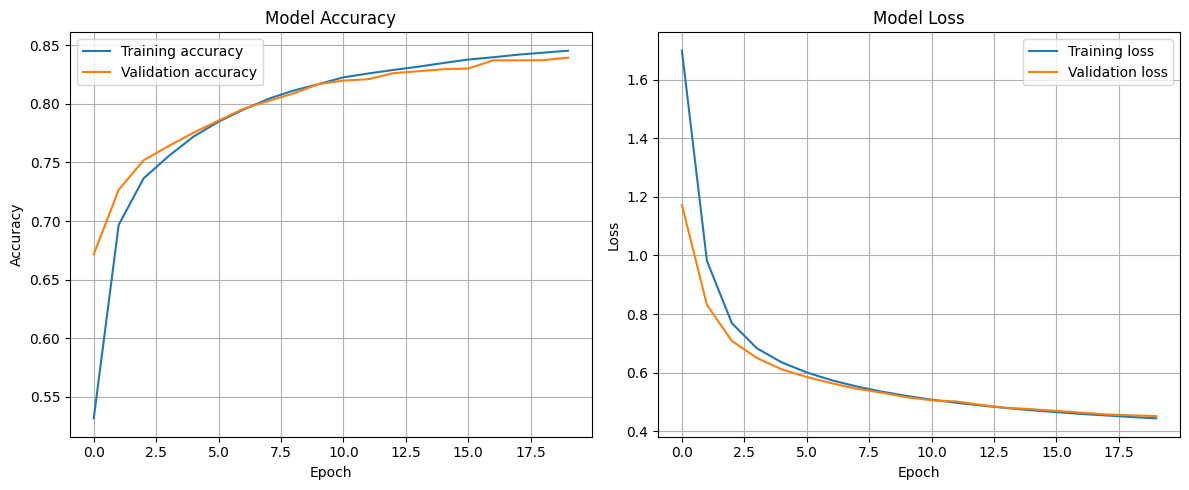

In [12]:
# Draw the learning curve here

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(hist.history['accuracy'], label='Training accuracy')
plt.plot(hist.history['val_accuracy'], label='Validation accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(hist.history['loss'], label='Training loss')
plt.plot(hist.history['val_loss'], label='Validation loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:
# Write your understanding about this model here
###
The training accuracy is expected to increase as the model learns to recognise patterns. In the same way, training loss should decrease with the improved accuracy of the model.
The validation curves represent the ability the model has to generalise images which have not been used to alter the weights.
If the training accuracy continues increasing and the testing accuracy does not improve, this is a sign of the model overfitting. Similarly, if testing loss decreases but validation loss stays the same or increases the model is overfitting.

To reduce overfitting, an early stop should be applied when validation accuracy does no longer grow with testing accuracy.
###

**Part 2- Image Processing**

Load the Flower photo dataset from tensorflow repository

In [16]:

import pathlib
import tarfile
import urllib.request
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import random
from PIL import Image

dataset_url = (
    "https://storage.googleapis.com/download.tensorflow.org/"
    "example_images/flower_photos.tgz"
)

data_root = pathlib.Path("/content/flower_data")
data_dir = data_root / "flower_photos"

if not data_dir.exists():
    data_root.mkdir(parents=True, exist_ok=True)
    archive_path = data_root / "flower_photos.tgz"

    urllib.request.urlretrieve(dataset_url, archive_path)

    with tarfile.open(archive_path, "r:gz") as archive:
        archive.extractall(data_root)

print("Dataset directory:", data_dir)
print("Directory exists:", data_dir.exists())
print("Subfolders:", sorted(
    folder.name for folder in data_dir.iterdir()
    if folder.is_dir()
))


# Find all image files in the five flower folders
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

all_images = [
    path for path in data_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

image_count = len(all_images)

print("Total number of images:", image_count)

for folder in sorted(data_dir.iterdir()):
    if folder.is_dir():
        count = sum(
            1 for path in folder.rglob("*")
            if path.is_file()
            and path.suffix.lower() in image_extensions
        )
        print(f"{folder.name}: {count} images")


Dataset directory: /content/flower_data/flower_photos
Directory exists: True
Subfolders: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Total number of images: 3670
daisy: 633 images
dandelion: 898 images
roses: 641 images
sunflowers: 699 images
tulips: 799 images


*a) How many images we can find in this dataset?*

3670 images



*b) The list of subfolders are:*
*   daisy
*   dandelion
*   roses
*   sunflowers
*   tulips

You can look into any of the subfolders to see images stored over there. You can look into the folder using: data_dir.glob('tulips/*')
For this part use Pillow (PIL) to show at least one flower from each subfolder


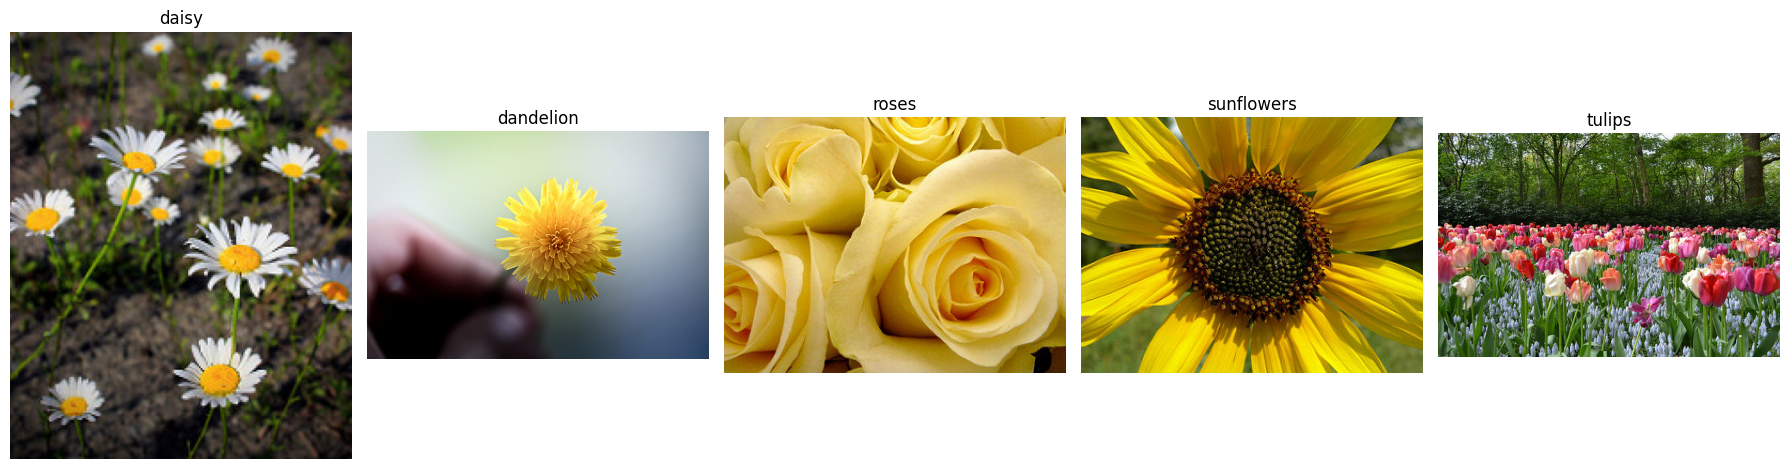

In [17]:
flower_classes = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, flower in zip(axes, flower_classes):
    flower_images = [
        p for p in (data_dir / flower).iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    if not flower_images:
        ax.set_title(f"No images: {flower}")
        ax.axis('off')
        continue

    image_path = random.choice(flower_images)

    # Pillow opens the image
    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(flower)
    ax.axis('off')

plt.tight_layout()
plt.show()


*c) Use Keras to resize all the images into same dimension 180x180*

In [19]:
batch_size = 32
img_height = 180
img_width = 180

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Class names: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Number of classes: 5


In [21]:
# Convert all the images in data_dir folder into 180x180 using tf.kera.utils.image_dataset_from_directory
# Modify following code
seed = 12345

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=seed,
    image_size=(img_height, img_width),
    batch_size=batch_size
)



Found 3670 files belonging to 5 classes.
Using 2936 files for training.


In [22]:
# Use the same strategy to create validation data, this time from validation subset
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

print("Class names:", train_ds.class_names)
print("Number of classes:", len(train_ds.class_names))

Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Class names: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Number of classes: 5


d) *You can use* `train_ds.class_names` *command to get the list of labels. Write a code to randomly show 9 images from training data while printing their label on top of the image.*

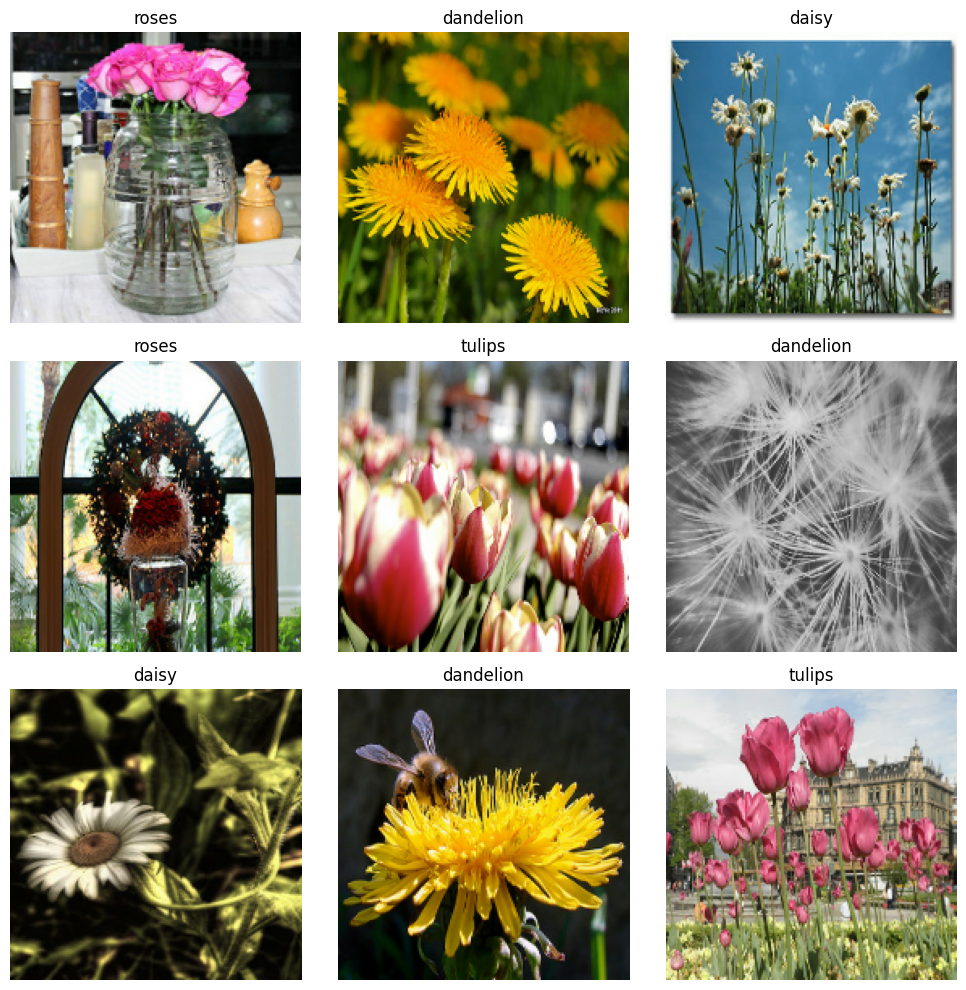

In [26]:
class_names = train_ds.class_names

# Get one batch of training images
for images, labels in train_ds.take(1):
    batch_count = images.shape[0]
    selected_indices = random.sample(
        range(batch_count),
        min(9, batch_count)
    )

    plt.figure(figsize=(10, 10))

    for plot_index, image_index in enumerate(selected_indices):
        ax = plt.subplot(3, 3, plot_index + 1)

        plt.imshow(
            images[image_index].numpy().astype("uint8")
        )

        label_index = int(labels[image_index].numpy())
        plt.title(class_names[label_index])
        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:
# Please carefully review the images. What are some barriers that you can see in images for having a proper classification?
###
From selecting multiple images at random, problems the algorithm has had are:
1) Distance: Pictures taken from far away or of multiple flowers from a distance are not well clasified.
2) Flower arrangements: When multiple kinds of flowers are presented in the same picture the algorithm cant define correctly their species.
3) Flowers as garments: When a flower is presented as a clothing item it isnt always classified correctly.
4) Lighting: When the light source is behind the flower, the algorithm has a higher chance of failing.
###

*e* - *Now, we want to use preprocessing package in Keras to apply different filters to the image. Apply the following procedures to image data:*
- *Rescale the image by dividing by 255*
- *Shear the image 20%*
- *Zoom the image 20%*
- *Horizontally flip the images*

In [27]:

from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

training_set = train_datagen.flow_from_directory(
    data_dir,
    target_size=(180, 180),
    batch_size=32,
    class_mode='sparse',
    shuffle=True,
    seed=123
)

print("Class indices:", training_set.class_indices)


Found 3670 images belonging to 5 classes.
Class indices: {'daisy': 0, 'dandelion': 1, 'roses': 2, 'sunflowers': 3, 'tulips': 4}


**2- OPENCV**- Now use opencv for preprocessing. Show first 9 images in dataset using Opencv. Before showing each image, resize the images to 180x180.

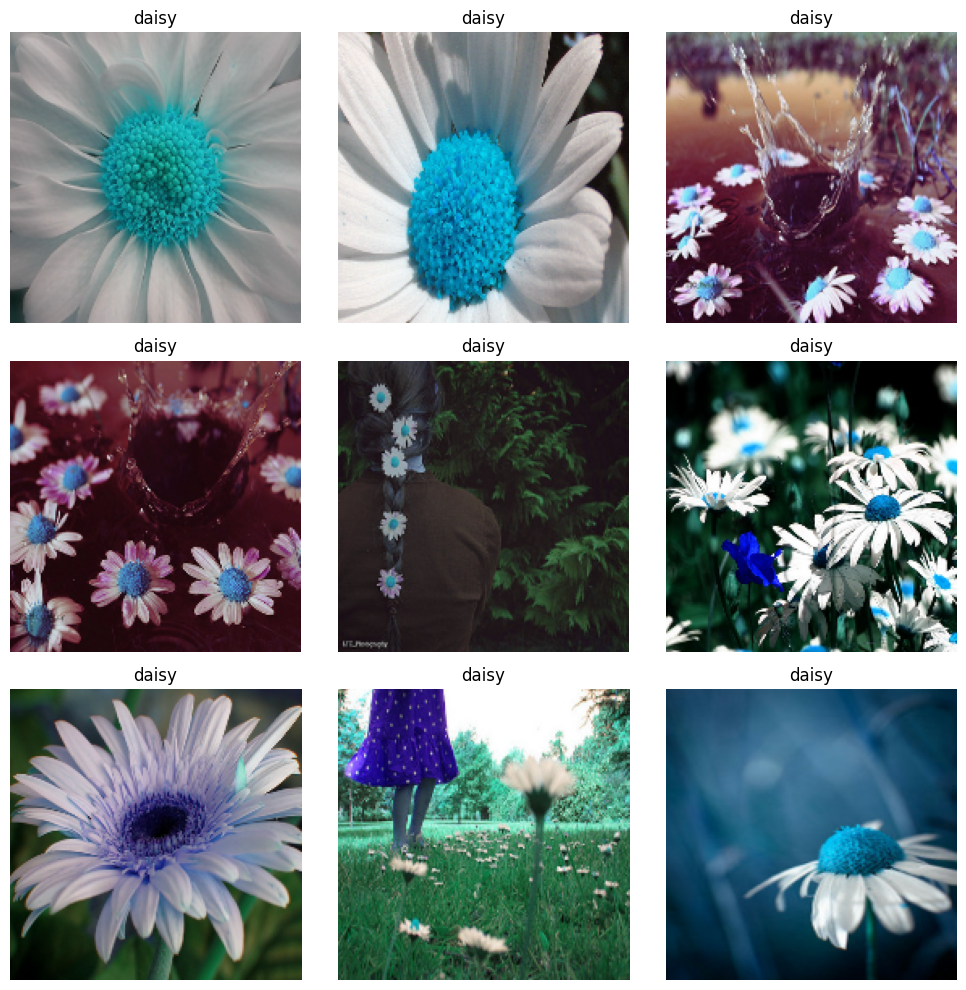

In [28]:
import cv2

# List all images in a consistent order
list_of_images = sorted([
    path for path in data_dir.rglob("*")
    if path.is_file()
    and path.suffix.lower() in image_extensions
])

fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    image_path = list_of_images[i]

    # Load the image using OpenCV (BGR format)
    img = cv2.imread(str(image_path))

    if img is None:
        ax.set_title("Could not load image")
        ax.axis("off")
        continue

    # Resize before displaying
    img_resized = cv2.resize(img, (180, 180))

    # Display the BGR image as loaded
    ax.imshow(img_resized)
    ax.set_title(image_path.parent.name)
    ax.axis("off")

plt.tight_layout()
plt.show()



OpenCV uses BGR as its default colour order for images, matplotlib uses RGB. When you display an image loaded with OpenCv in matplotlib the channels will be back to front.
The easiest way of fixing this is to use OpenCV to explicitly convert it back to RGB, much like you do when creating the greyscale image.


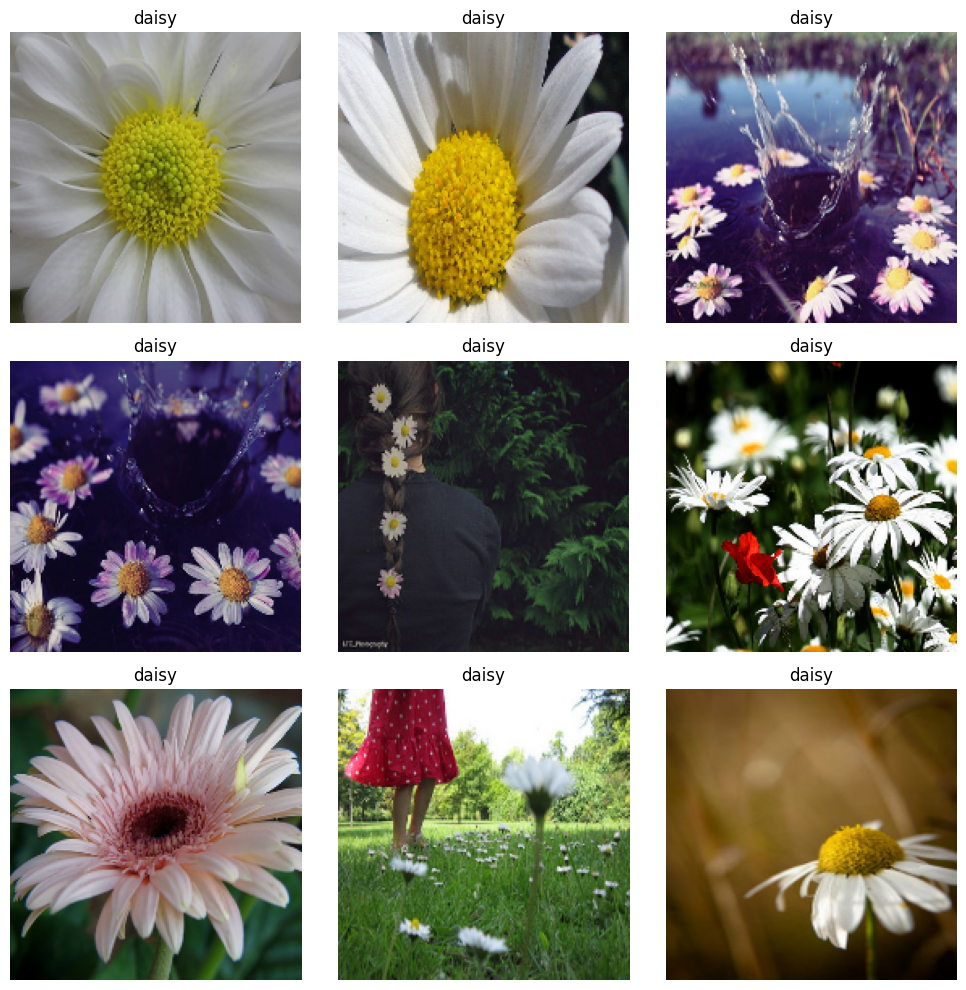

In [29]:
# That was good but I need natural color so create the RGB version of above images.

fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    image_path = list_of_images[i]

    # Read image in BGR format
    img = cv2.imread(str(image_path))

    if img is None:
        ax.set_title("Could not load image")
        ax.axis("off")
        continue

    # Resize to 180 x 180
    img_resized = cv2.resize(img, (180, 180))

    # Convert BGR to RGB
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)

    # Display image with natural colors
    ax.imshow(img_rgb)
    ax.set_title(image_path.parent.name)
    ax.axis("off")

plt.tight_layout()
plt.show()


This part onward is to create a pdf from this ipynb file. You can use these 3 cells throughout the semester tio create the pdf files.

In [31]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [30]:
!apt-get install texlive texlive-xetex texlive-latex-extra pandoc
!pip install pypandoc


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
pandoc is already the newest version (3.1.3+ds-2).
pandoc set to manually installed.
The following additional packages will be installed:
  at-spi2-common at-spi2-core default-jre default-jre-headless dvisvgm
  fonts-dejavu-core fonts-dejavu-extra fonts-dejavu-mono fonts-droid-fallback
  fonts-lato fonts-lmodern fonts-noto-mono fonts-texgyre fonts-texgyre-math
  fonts-urw-base35 gsettings-desktop-schemas libapache-pom-java
  libatk-bridge2.0-0t64 libatk-wrapper-java libatk-wrapper-java-jni
  libatk1.0-0t64 libatspi2.0-0t64 libbit-vector-perl libcarp-clan-perl
  libcommons-logging-java libcommons-parent-java libcrypt-rc4-perl
  libdate-calc-perl libdate-calc-xs-perl libdate-manip-perl
  libdigest-perl-md5-perl libfontbox-java libgs-common libgs10 libgs10-common
  libgtk-3-0t64 libgtk-3-bin libgtk-3-common libgumbo2 libidn12 libijs-0.35
  libio-stringy-perl libjbig2dec0 libjcode-pm-perl libkp

In [33]:
%shell jupyter nbconvert --to pdf 'JuanTorres_assignment1.ipynb'

[NbConvertApp] WARNING | pattern 'JuanTorres_assignment1.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
--

CalledProcessError: Command 'jupyter nbconvert --to pdf 'JuanTorres_assignment1.ipynb'' returned non-zero exit status 255.